In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv("dataset.csv")
df = df.drop(columns=["Unnamed: 0"])
df = df.dropna()
df = df.drop_duplicates()

In [20]:
valgte_sjangre = ["swedish", "acoustic", "k-pop", "rock", "disco", "salsa"]

df_klynge = df[df["track_genre"].isin(valgte_sjangre)].copy()

features = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness",
    "valence", "tempo",
]

X = df_klynge[features]

In [21]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

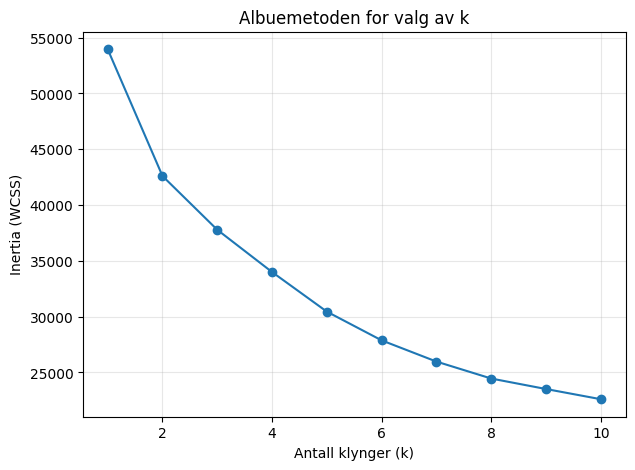

In [22]:
inertia = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=1, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(list(k_range), inertia, marker="o")
plt.xlabel("Antall klynger (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Albuemetoden for valg av k")
plt.grid(alpha=0.3)
plt.show()

In [25]:
k_valgt = 3

kmeans = KMeans(n_clusters=k_valgt, random_state=1, n_init=10)
df_klynge["klynge"] = kmeans.fit_predict(X_scaled)

pd.crosstab(df_klynge["klynge"], df_klynge["track_genre"])

track_genre,acoustic,disco,k-pop,rock,salsa,swedish
klynge,,,,,,
0,40,93,9,12,13,20
1,276,748,719,722,845,644
2,684,159,270,266,140,336
